# Predicting machine failure on a milling machine, and deciding when to stop it

**IDSE course project, Part A.** Dataset: [AI4I 2020 Predictive Maintenance](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) (UCI Machine Learning Repository).

## 1. Problem

A milling machine logs air and process temperature, spindle speed, torque and tool wear for every job. A small share of jobs end in a machine failure. When a failure is missed the shop pays for an unplanned breakdown (scrapped part, damaged tool, downtime). When the alarm is raised for nothing, the shop pays for a short stop and inspection.

**Question:** from the sensor readings at the start of a job, can we flag the jobs likely to fail, and where should the alarm threshold sit so that the **total cost of mistakes is as low as possible**?

**Measurable goals**
1. Beat two baselines on held-out data: *never raise an alarm*, and the usual shop rule *replace the tool at 200 min of wear*.
2. Report the cost in rupees at an assumed ₹50,000 per missed failure and ₹2,000 per false alarm, and show the conclusion holds for cost ratios from 5:1 to 100:1.
3. Explain which failure types the model catches and misses, and what operating region it considers unsafe.

**Why this dataset.** It is a public benchmark released with a peer-reviewed paper (Matzka, AI4I 2020 conference). It has 10,000 rows (enough for a proper train/validation/test design) and is directly about machining, which fits a mechanical engineering course. It is *synthetic*: its authors generated it to mirror real machine behaviour, because real failure logs are rarely published. That limits how far the results transfer to a real shop, which section 9 discusses.

In [1]:
# Setup: make the project's src/ package importable and fix every random seed (inside src/config.py).
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%matplotlib inline
import pandas as pd
from src import config, data, evaluate, features, models, pipeline, plots

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
print("Random seed:", config.SEED)

Random seed: 42


## 2. Data loading and quality checks

Before cleaning anything, we measure what is in the file: types, missing values, duplicates, how rare failures are, and whether the labels agree with each other.

In [2]:
raw, df, report, cleaning_log = pipeline.load_and_clean()
raw.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
{k: v for k, v in report.items() if k != "dtypes"}

{'rows': 10000,
 'columns': 14,
 'missing_values': {},
 'duplicate_rows_ignoring_id': 0,
 'duplicate_product_ids': 0,
 'failure_rate': 0.0339,
 'failures': 339,
 'mode_counts': {'TWF': 46, 'HDF': 115, 'PWF': 95, 'OSF': 98, 'RNF': 19},
 'rows_with_multiple_modes': 24,
 'failure_without_mode': 9,
 'mode_without_failure': 18,
 'mode_without_failure_by_mode': {'TWF': 0,
  'HDF': 0,
  'PWF': 0,
  'OSF': 0,
  'RNF': 18},
 'type_counts': {'L': 6000, 'M': 2997, 'H': 1003},
 'product_id_letter_matches_type': True}

**What the checks show**


* **Size and types.** The file has 10,000 rows and 14 columns. Type (L/M/H) is categorical, and the rest are numeric. The file starts with a byte-order mark, which the loader handles.
* **Missing values and duplicates.** There are no missing values, no duplicate rows (ignoring the ID columns) and no repeated product IDs.
* **Rare target.** 339 of 10,000 jobs failed (3.39%). That one fact drives the choice of metric and threshold later on.
* **Label inconsistencies found:**
    * 9 rows have `Machine failure = 1` but no failure mode flagged. The machine stopped, but the cause was not recorded.
    * 18 rows have the random-failure flag (RNF) set but `Machine failure = 0`. Only 1 of the 19 RNF rows is actually a failure.
    * We keep `Machine failure` as the ground truth because it records the event we care about. The mode flags are used only to explain errors.
* **Redundant ID.** The first letter of `Product ID` always equals `Type`, so `Product ID` adds nothing and is not a feature.


## 3. Cleaning, with the reason for each step

In [4]:
for step in cleaning_log:
    print("-", step)

- Renamed columns to snake_case with units kept (e.g. 'Torque [Nm]' -> torque_nm).
- Type -> ordered category L < M < H (low, medium, high product quality).
- No missing values, so no imputation is needed. A median imputer still sits inside the model pipeline so it would be fitted on training data only if new data had gaps.
- No duplicate rows (ignoring the ID columns) and no repeated product IDs.
- udi and product_id are identifiers, not measurements; they are kept for tracing rows but never used as features (product_id's first letter only repeats Type).
- Label check: 9 failures have no mode flagged (labelled 'unknown'), and 18 rows have a mode flagged but machine_failure = 0. machine_failure is kept as the ground truth because it records whether the machine actually stopped.
- TWF/HDF/PWF/OSF/RNF describe HOW a failure happened, so they are only known after the event. They are excluded from the features (using them would be target leakage) and used only for error analysis.
- IQR out

In [5]:
# Outliers by the 1.5 x IQR rule, and how often those rows fail compared with the rest.
data.iqr_outliers(df)

,feature,lower_fence,upper_fence,n_outliers,failure_rate_in_outliers,failure_rate_elsewhere
0,air_temp_k,293.50,306.30,0,NaN,0.034
1,process_temp_k,305.35,314.55,0,NaN,0.034
2,rpm,1139.50,1895.50,418,0.084,0.032
3,torque_nm,12.80,67.20,69,0.899,0.028
4,tool_wear_min,-110.50,325.50,0,NaN,0.034



**Outlier decision.** The 1.5×IQR rule flags 418 speed readings and 69 torque readings, and nothing in temperature or tool wear. These rows are not errors:

* The flagged **torque** readings fail **90%** of the time, against 2.8% for the rest.
* The flagged **speed** readings fail 8.4% of the time, against 3.2%.

Removing them would throw away the clearest failure signal, so all of them are kept. Tree models are not distorted by extreme values, and the scaler inside the pipeline handles the linear model.


## 4. Exploratory data analysis

Each plot is followed by what it tells us.

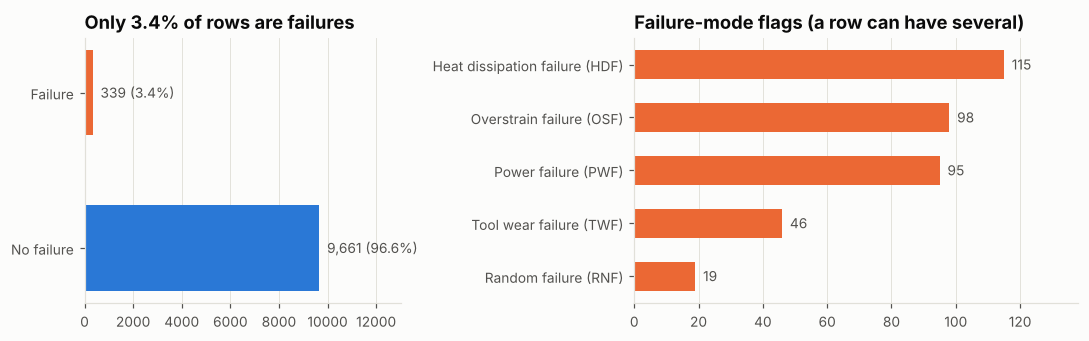

In [6]:
_ = plots.class_balance(df)


**Insight.** Only 3.4% of jobs fail. A "model" that always says *no failure* would be 96.6% accurate and completely useless, so accuracy is not used to choose models. Among the failure modes, heat dissipation (115), overstrain (98) and power (95) are the most common. Tool wear (46) and random failures (19) are rarer, and 24 failures have more than one mode flagged.


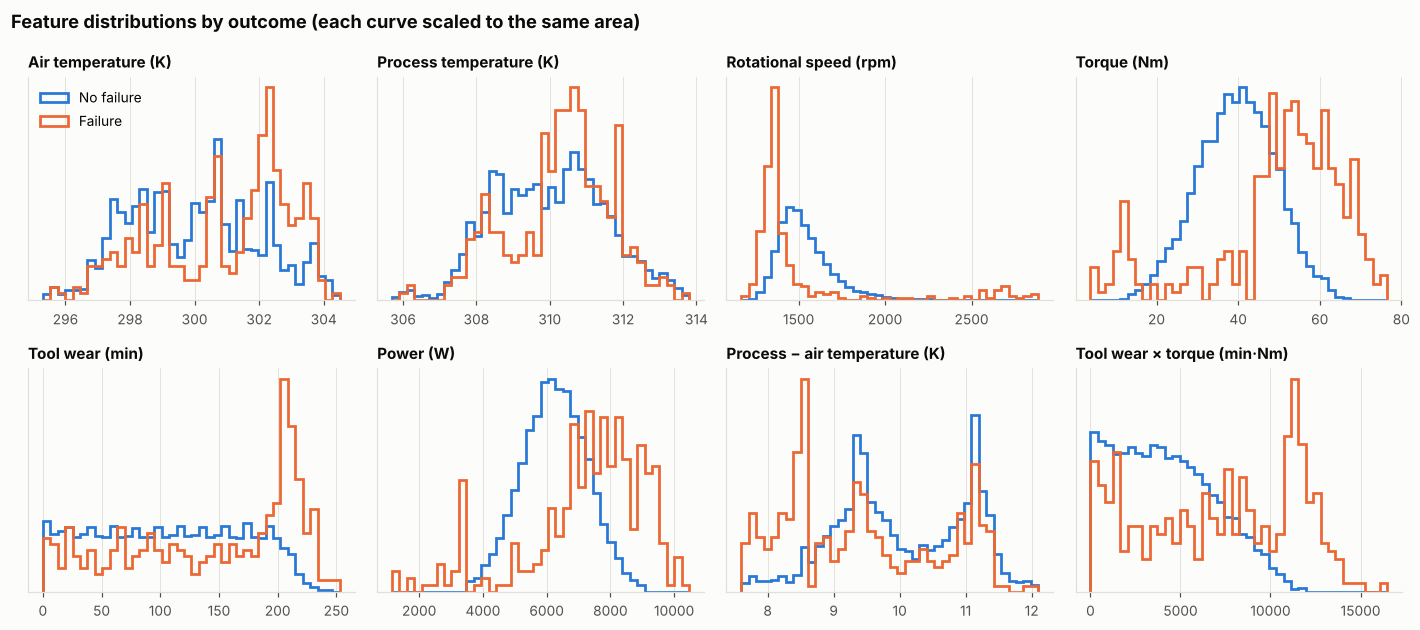

In [7]:
_ = plots.distributions(df, data.RAW_NUMERIC + features.ENGINEERED)


**Insights**

* **Speed and torque separate the classes most clearly.** Failures pile up below about 1,400 rpm and above 2,500 rpm, and at torque above about 50 Nm or below about 20 Nm.
* **Tool wear matters only at the end of tool life.** Below 200 min, the two curves overlap. Above 200 min, failures dominate.
* **Power and the temperature difference fail on a *band*.** Failures appear when power is too low *or* too high, and when the process runs less than about 8.6 K above ambient.
* **Air and process temperature on their own barely differ between classes.** Their *difference* is what matters.


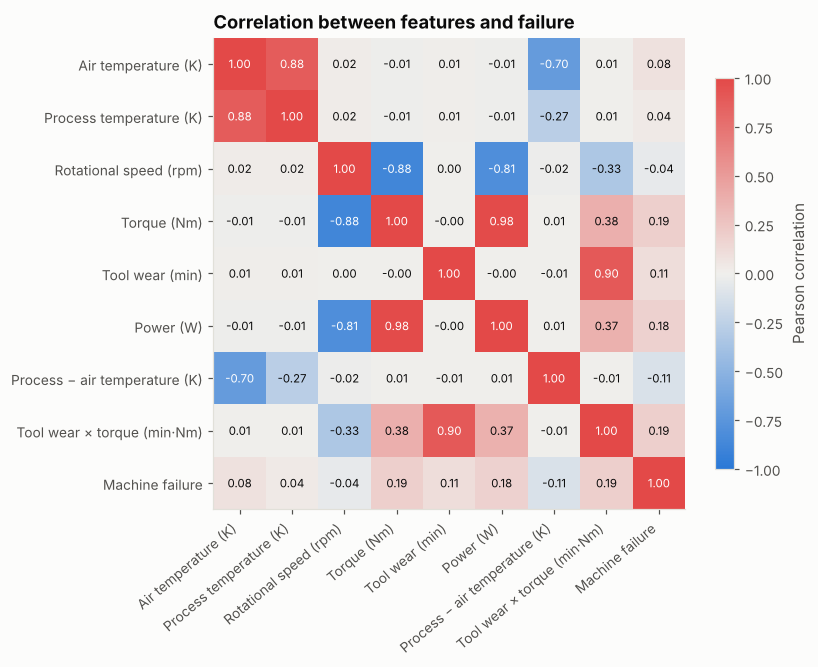

In [8]:
_ = plots.correlation(df, data.RAW_NUMERIC + features.ENGINEERED)


**Insights**

* **Two strong pairs.** Air and process temperature correlate at 0.88, because the process heats up from the air temperature. Speed and torque correlate at −0.88, because the machine runs at roughly constant power. Strongly correlated features make linear-model coefficients unstable to interpret, but they do not hurt tree models.
* **Weak linear signal.** No feature correlates with failure above 0.19 (torque and wear × torque). That does **not** mean the signal is weak: failure happens at *both ends* of power and speed, and a correlation coefficient can't see a two-sided pattern. This predicts that a linear model will struggle and that tree models, which split ranges into pieces, will do much better. Section 7 confirms this.


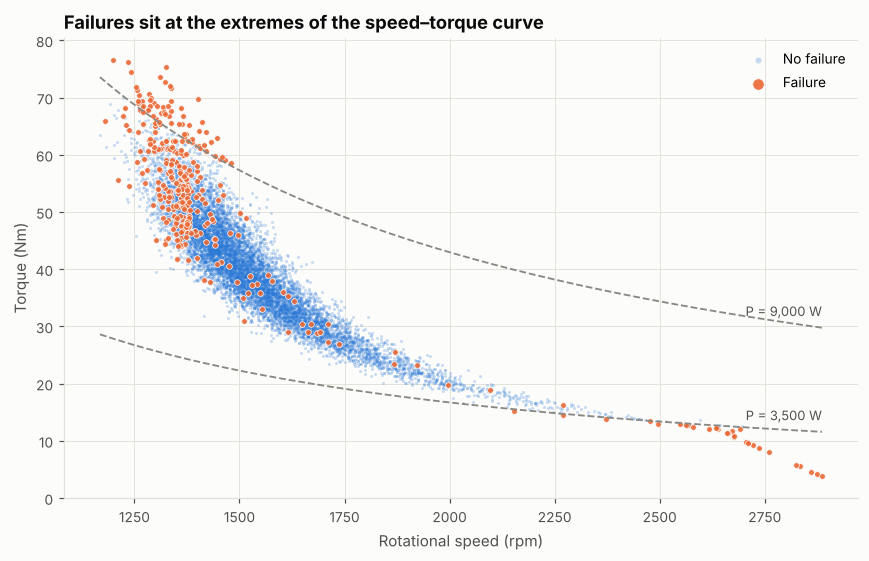

In [9]:
_ = plots.rpm_torque(df)


**Insight.** The operating points follow a hyperbola, torque × speed ≈ constant, which means the machine runs near constant power. The dashed lines mark 3,500 W and 9,000 W. Failures sit in two places: the top-left corner (high torque at low speed, above 9 kW) and the bottom-right tail (low torque at high speed, below 3.5 kW). The cluster at about 1,300–1,400 rpm and 45–60 Nm is mostly heat-dissipation and overstrain failures. This plot is why spindle power should be a feature.


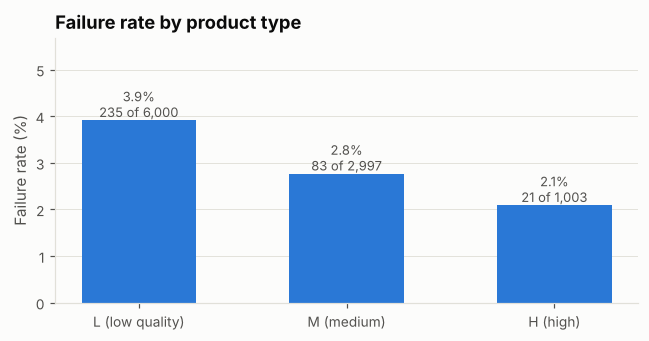

In [10]:
_ = plots.failure_by_type(df)


**Insight.** Low-quality (L) parts fail at 3.9% (235 of 6,000), medium (M) at 2.8% (83 of 2,997) and high (H) at 2.1% (21 of 1,003). L parts fail almost twice as often as H parts, which fits the dataset documentation: L parts tolerate less overstrain. Type is therefore kept as a feature. With only 21 failures, any conclusion specific to H parts is uncertain.


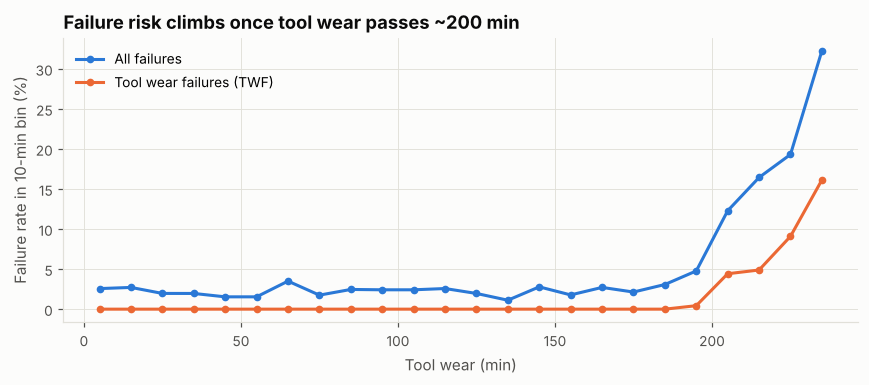

In [11]:
_ = plots.tool_wear_rate(df)


**Insight.** Up to about 180 min of wear, the failure rate is flat at 2–3%. It jumps to 12% between 200 and 210 min (50 of 407 jobs) and to 32% between 230 and 240 min. Tool-wear failures appear only from 198 min onward. Much of the rise near 200 min is also overstrain, because a worn tool under heavy torque breaks. A fixed "replace at 200 min" rule acts in the right region, but it can't see heat or power failures, which happen at any wear level.


## 5. Feature engineering

The raw sensors describe the job; the physics of cutting tells us which combinations matter. Three features follow directly from machining theory:

| Feature | Formula | Why it should matter |
| --- | --- | --- |
| Spindle power, W | P = T × ω = torque × rpm × 2π / 60 | Motor and drive have a safe power band |
| Temperature difference, K | process − air temperature | Small difference means heat is not leaving the cutting zone |
| Tool wear × torque, min·Nm | wear × torque | A worn tool under heavy load is likely to break |

All three are computed row by row from that row alone, so they cannot leak information between train and test.

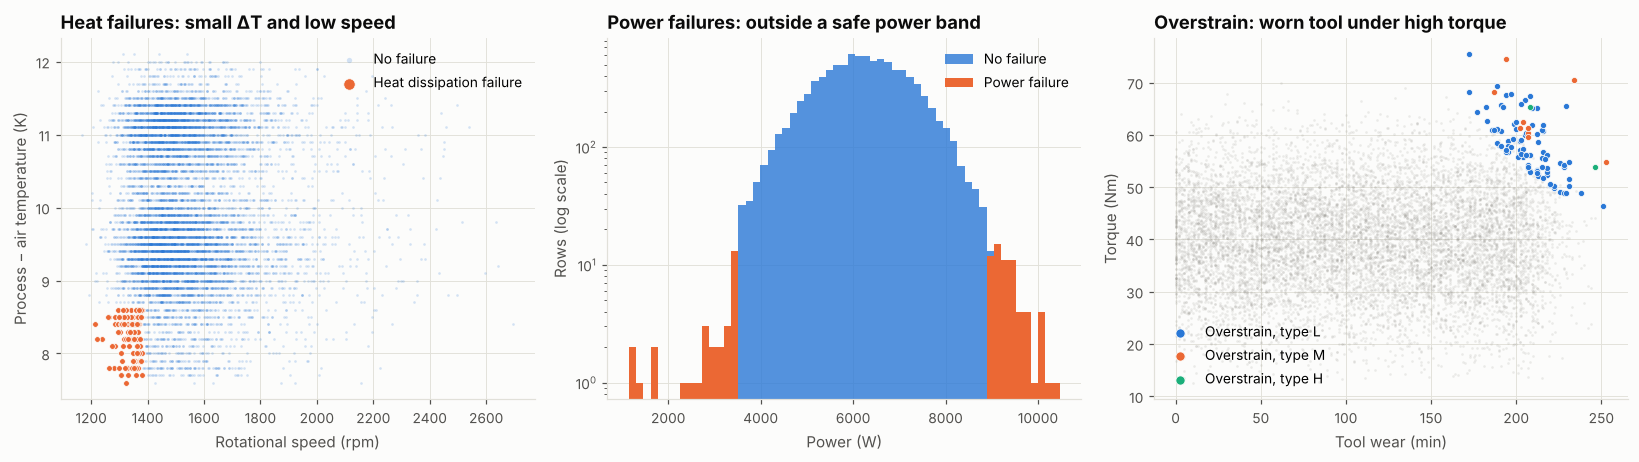

In [12]:
_ = plots.physics_views(df)


**Insights.** Each engineered feature isolates one failure mode with a sharp boundary:

* **Heat dissipation:** all 115 cases have a temperature difference below about 8.6 K *and* speed below about 1,380 rpm. They form a clean rectangle.
* **Power:** every power failure lies below about 3,500 W or above about 9,000 W.
* **Overstrain:** failures appear where tool wear × torque passes about 11,000 min·Nm for L parts (higher for M and H).

These boundaries match the rules the dataset's authors describe, which confirms the data was generated from machining physics. It also explains why the physics features should help: each one turns a curved boundary in raw-sensor space into a single cut.


## 6. Validation design (how we avoid fooling ourselves)

* **Test set locked away.** 20% of the rows, stratified so it has the same failure rate, is set aside now and used **once**, at the very end.
* **Model choices on training data only.** Feature-set comparison, hyper-parameter tuning, threshold choice and picking the final model all use 5-fold stratified cross-validation on the remaining 80%.
* **No preprocessing leakage.** Imputation, scaling and one-hot encoding live inside a scikit-learn `Pipeline`, so in every fold they are fitted on that fold's training part only.
* **No target leakage.** The five failure-mode flags (TWF, HDF, PWF, OSF, RNF) are only known *after* a failure, so they are never features.
* **Metric for rare events.** With about 3% failures, a model that never raises an alarm is 97% "accurate". So we rank models by **PR-AUC** (area under the precision–recall curve) and make the final decision by **cost**.

In [13]:
train, test = pipeline.split(df)
print(f"train: {len(train):,} rows, {train[config.TARGET].sum()} failures ({train[config.TARGET].mean():.2%})")
print(f"test:  {len(test):,} rows, {test[config.TARGET].sum()} failures ({test[config.TARGET].mean():.2%})")

train: 8,000 rows, 271 failures (3.39%)
test:  2,000 rows, 68 failures (3.40%)


## 7. Modelling

**Baselines** (no learning): *never alarm*, and *replace the tool at 200 min of wear*, which is a common time-based maintenance rule.

**Three approaches**, from simple to flexible:

* **Logistic regression**, a linear model. It is easy to explain, but it can only draw one straight boundary in feature space.
* **Random forest**, many decision trees on random subsets. It handles thresholds and interactions without needing scaled data.
* **Gradient boosting** (`HistGradientBoostingClassifier`), trees built one after another, each correcting the last. This is usually the strongest choice on tabular data.

Class imbalance is handled with class weights for the first two models. For all three, the cost-based threshold in step 8 moves the alarm point.

### 7.1 Do the physics features help?

In [14]:
ablation = pipeline.ablation(train)
ablation

,raw,engineered
Logistic regression,0.432,0.455
Random forest,0.746,0.891
Gradient boosting,0.802,0.885


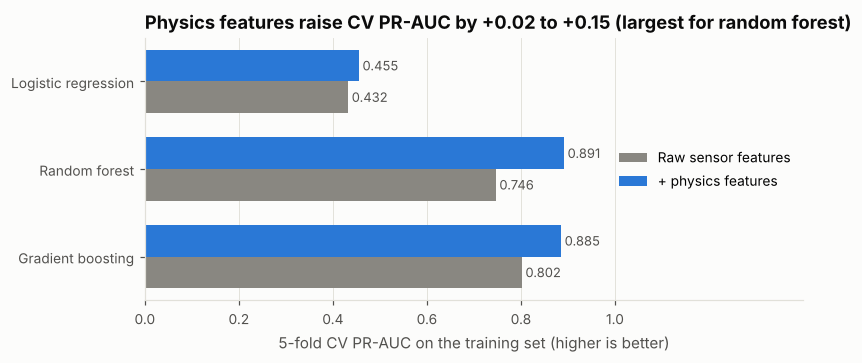

In [15]:
_ = plots.feature_ablation(ablation, pipeline.ablation_title(ablation))


**Result.** Adding the three physics features raises cross-validated PR-AUC for every model:

* Random forest: 0.746 → 0.891 (+0.145)
* Gradient boosting: 0.802 → 0.885 (+0.083)
* Logistic regression: 0.432 → 0.455 (+0.023)

The tree models gain most because they can now cut once on power instead of approximating the hyperbola P = T·ω with many rectangular splits. Logistic regression gains little: even with power available, failure is dangerous at *both* ends of the band, and one linear weight can't say "too low or too high". **Decision:** use the engineered feature set from here on.


### 7.2 Hyper-parameter tuning (grid search, 5-fold CV, scored by PR-AUC)

In [16]:
searches, tuned = pipeline.tune(train)
tuned

,cv_pr_auc,best_params
model,,
Logistic regression,0.486,{'C': 0.1}
Random forest,0.897,"{'max_depth': 16, 'max_features': 0.5, 'min_sa..."
Gradient boosting,0.893,"{'l2_regularization': 1.0, 'learning_rate': 0...."



**Result.** Tuning adds a little on top of the features:

| Model | PR-AUC after features | After tuning | Chosen settings |
| --- | --- | --- | --- |
| Logistic regression | 0.455 | 0.486 | C = 0.1 |
| Random forest | 0.891 | 0.897 | max_depth 16, min_samples_leaf 3, max_features 0.5 |
| Gradient boosting | 0.885 | 0.893 | learning rate 0.03, 200 trees, 15 leaves, L2 = 1 |

Random forest and gradient boosting are within 0.004 of each other, which is less than the variation between folds. Most of the improvement came from feature engineering, not from tuning.


## 8. Choosing the alarm threshold by cost

A classifier outputs a probability, and 0.5 is an arbitrary cut-off. A missed failure costs about 25 times more than a false alarm (₹50,000 vs ₹2,000, assumed), so the alarm should go off at a much lower probability. For each model we take **out-of-fold** probabilities on the training set and pick the threshold with the lowest total cost. The model with the lowest cross-validated cost becomes the final model. All of this happens before the test set is used.

In [17]:
oof, thresholds, best = pipeline.thresholds(train, searches)
print("Final model (lowest cross-validated cost):", best)
thresholds

Final model (lowest cross-validated cost): Gradient boosting


,threshold,oof_cost_rs,oof_cost_at_0.5_rs,oof_recall,oof_precision
model,,,,,
Logistic regression,0.515,4578000,4612000,0.830,0.165
Random forest,0.069,1714000,2138000,0.952,0.327
Gradient boosting,0.016,1680000,2776000,0.945,0.355


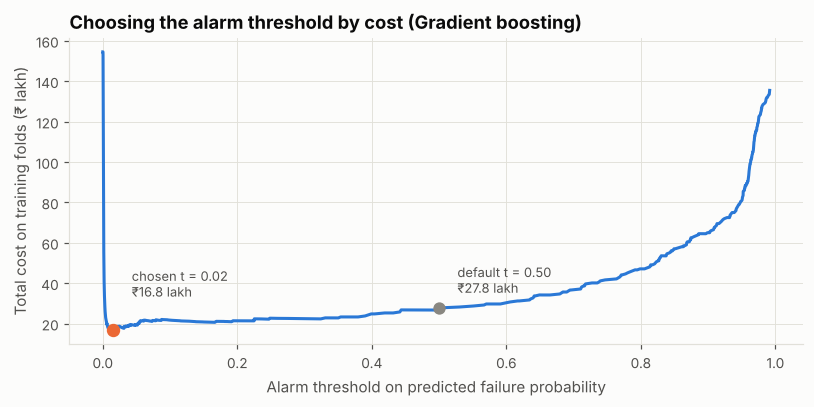

In [18]:
_ = plots.cost_vs_threshold(evaluate.cost_curve(train[config.TARGET], oof[best]),
                            thresholds.loc[best, "threshold"], best)


**Result.** The cost curve is very high at threshold 0 (every job stopped) and at threshold 1 (every failure missed), with a wide, flat bottom between about 0.02 and 0.3. That flat bottom means the choice is not fragile.

* **Gradient boosting** has the lowest cross-validated cost: ₹16.8 lakh at threshold 0.016, against ₹27.8 lakh at the default 0.5. That is 40% cheaper just from moving the threshold.
* **Random forest** is a close second at ₹17.1 lakh (threshold 0.068).
* **Logistic regression** costs ₹45.8 lakh, far behind.

**Why the threshold is so low.** Raise an alarm when the expected cost of staying quiet exceeds the cost of stopping: p × 50,000 > (1 − p) × 2,000, which gives **p > 2,000 / 52,000 ≈ 0.04**. The model's choice of 0.016 is in that range, since boosted-tree probabilities are not perfectly calibrated. Logistic regression's threshold stays near 0.5 because its balanced class weights have already pushed its probabilities up.


## 9. Evaluation on the held-out test set

In [19]:
results, probas, preds = pipeline.test_eval(train, test, searches, thresholds)
results[["threshold", "precision", "recall", "f1", "accuracy", "pr_auc", "roc_auc", "fn", "fp", "cost_rs"]]

,threshold,precision,recall,f1,accuracy,pr_auc,roc_auc,fn,fp,cost_rs
Never alarm (majority class),0.500,0.000,0.000,0.000,0.966,NaN,NaN,68.0,0.0,3.400e+06
Replace tool at 200 min wear,0.500,0.149,0.382,0.214,0.904,NaN,NaN,42.0,149.0,2.398e+06
Logistic regression,0.515,0.176,0.868,0.292,0.857,0.440,0.931,9.0,277.0,1.004e+06
Logistic regression @ 0.5,0.500,0.170,0.882,0.285,0.850,0.440,0.931,8.0,293.0,9.860e+05
Random forest,0.069,0.323,0.926,0.479,0.931,0.891,0.979,5.0,132.0,5.140e+05
Random forest @ 0.5,0.500,0.933,0.824,0.875,0.992,0.891,0.979,12.0,4.0,6.080e+05
Gradient boosting,0.016,0.351,0.956,0.514,0.939,0.915,0.987,3.0,120.0,3.900e+05
Gradient boosting @ 0.5,0.500,0.966,0.824,0.889,0.993,0.915,0.987,12.0,2.0,6.040e+05


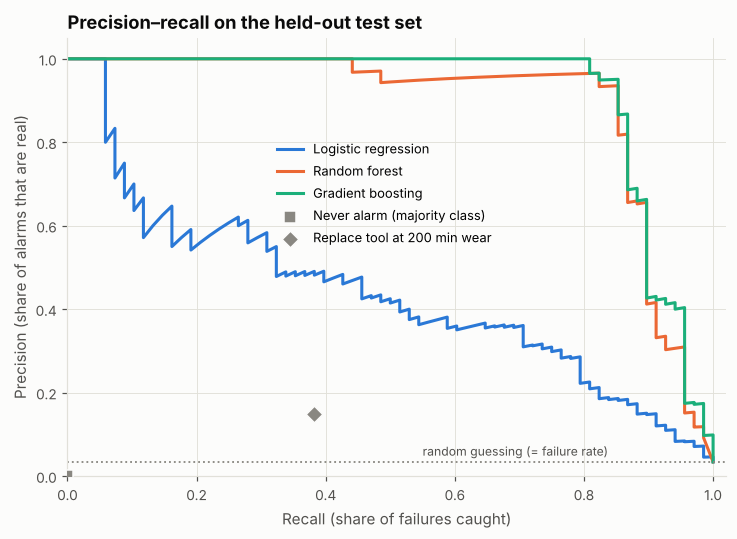

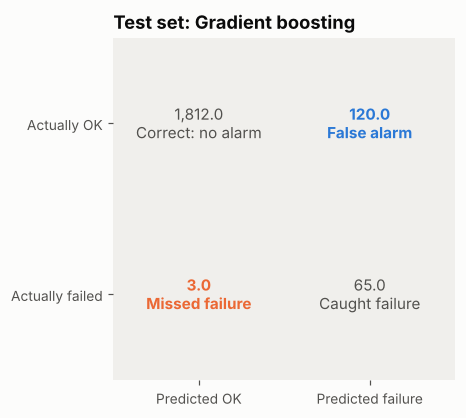

In [20]:
baselines = models.make_baselines()
_ = plots.pr_curves(test[config.TARGET], probas,
                    {n: (results.loc[n, "recall"], results.loc[n, "precision"]) for n in baselines})
r = results.loc[best]
_ = plots.confusion(r["tp"], r["fp"], r["fn"], r["tn"], best)

In [21]:
# How much could these numbers move with a different sample of 2,000 jobs? (1,000 bootstrap resamples)
evaluate.bootstrap_ci(test[config.TARGET], probas[best], thresholds.loc[best, "threshold"])

,estimate,ci_low_2.5%,ci_high_97.5%
recall,0.956,0.900,1.000
precision,0.351,0.281,0.421
cost_rs,390000.000,236000.000,578000.000



**Result on the 2,000 held-out jobs (68 failures).** These numbers were seen once, after every choice was made.

| | Failures caught | False alarms | Cost |
| --- | --- | --- | --- |
| Never alarm | 0 of 68 | 0 | ₹34.0 lakh |
| Replace tool at 200 min | 26 of 68 | 149 | ₹24.0 lakh |
| Logistic regression | 59 of 68 | 277 | ₹10.0 lakh |
| Random forest | 63 of 68 | 132 | ₹5.1 lakh |
| **Gradient boosting (final)** | **65 of 68 (95.6%)** | **120** | **₹3.9 lakh** |
| Gradient boosting at default 0.5 | 56 of 68 | 2 | ₹6.0 lakh |

* The final model cuts the cost of mistakes by **89%** against doing nothing and by **84%** against the 200-minute replacement rule. It inspects 6.2% of healthy jobs (120 of 1,932).
* **Accuracy and F1 point the wrong way.** At 0.5 the same model is more accurate (99.3% vs 93.9%) and has a higher F1, yet it costs 55% more because it misses 12 failures instead of 3. The metric has to match the decision.
* **Uncertainty.** A bootstrap of the test set gives a 95% interval of 90–100% for recall and ₹2.4–5.8 lakh for cost. The worst case is still far below both baselines.
* **No sign of overfitting.** Test PR-AUC (0.915) is in line with cross-validation (0.893).


### 9.1 Error analysis: which failures are missed, and why?

,failures,caught,recall
Heat dissipation failure (HDF),28,28,1.000
Overstrain failure (OSF),15,15,1.000
Power failure (PWF),12,12,1.000
Tool wear failure (TWF),9,7,0.778
Several modes at once (multiple),2,2,1.000
No mode recorded (unknown),2,1,0.500


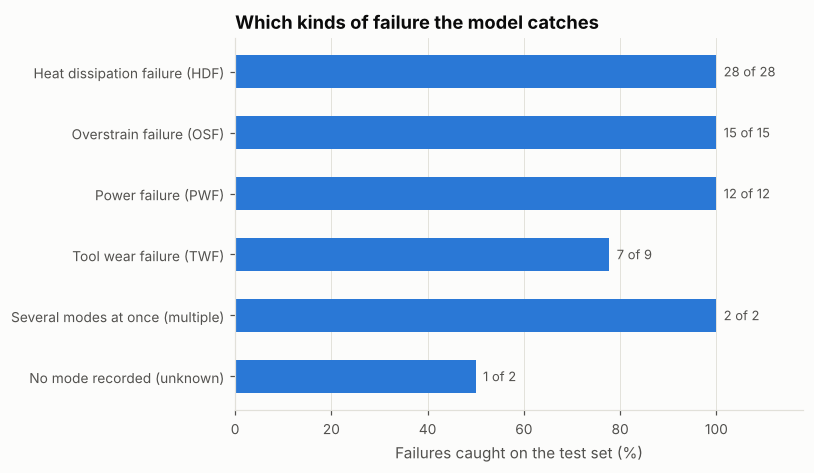

In [22]:
by_mode, missed, false_alarms, importance = pipeline.error_analysis(test, best, searches, probas, preds)
_ = plots.recall_modes(by_mode)
by_mode

In [23]:
missed  # every failure in the test set that the final model did not flag

,type,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,power_w,temp_diff_k,strain_min_nm,failure_mode,p_fail
121,L,297.8,308.9,1871,25.6,200,5015.82,11.1,5120.0,TWF,0.0
1657,L,298.4,309.6,1710,27.3,163,4888.63,11.2,4449.9,unknown,0.0
1866,M,298.4,308.0,1416,38.2,198,5664.42,9.6,7563.6,TWF,0.0


In [24]:
# False alarms vs correctly-quiet rows: are the false alarms near a danger zone?
quiet = test[(test[config.TARGET] == 0) & (preds[best] == 0)]
pd.DataFrame({"false alarms (mean)": false_alarms[features.ENGINEERED + ["tool_wear_min", "rpm"]].mean(),
              "correct no-alarm (mean)": quiet[features.ENGINEERED + ["tool_wear_min", "rpm"]].mean()})

,false alarms (mean),correct no-alarm (mean)
power_w,6315.345,6228.212
temp_diff_k,9.860,10.033
strain_min_nm,7886.547,4010.047
tool_wear_min,199.542,101.357
rpm,1529.067,1539.077



**What is missed.** All heat (28 of 28), overstrain (15 of 15), power (12 of 12) and multi-mode (2 of 2) failures in the test set are caught. The three misses are:

* **Two tool-wear failures**, at 198 and 200 min of wear and moderate torque (26 and 38 Nm). According to the dataset documentation, a tool fails at a *random* wear time between 200 and 240 min. Two tools with identical readings can differ only by chance, so no model can predict these reliably. This is a limit of the data, not of the model.
* **One failure with no recorded mode.** With no mode recorded, it has no physical pattern to learn.

**What the false alarms are.** 108 of the 120 false alarms (90%) are jobs with tool wear of 190 min or more. The average false alarm is at 200 min of wear, against 101 min for correctly quiet jobs. In other words, the model stops jobs whose tool is in the window where tool-wear failure becomes possible. On the shop floor, an inspection at that point is close to a planned tool change anyway, so the real cost of these alarms is probably below the assumed ₹2,000.


### 9.2 What the model relies on, and the safe operating envelope

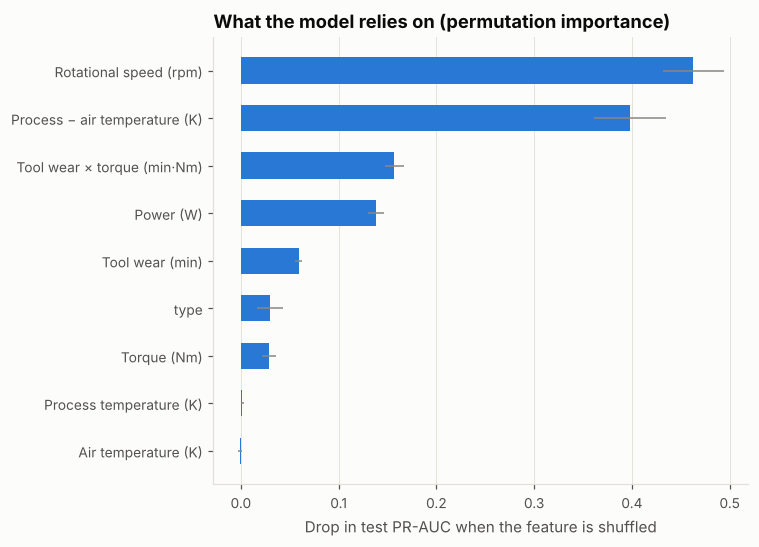

In [25]:
_ = plots.importance(importance)

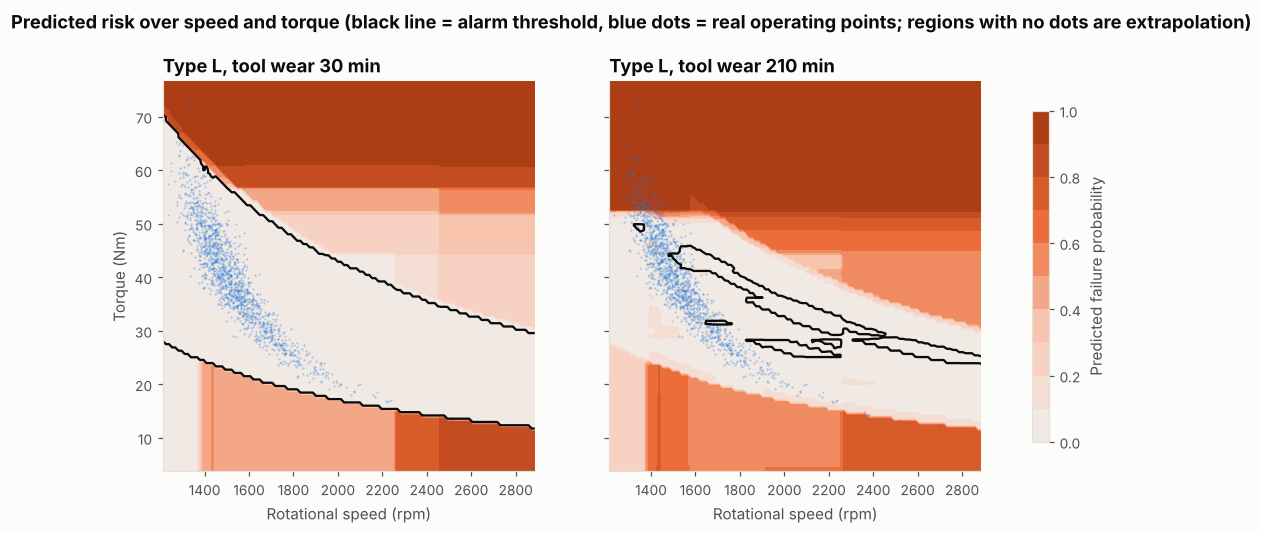

In [26]:
_ = plots.risk_map(searches[best].best_estimator_, df, thresholds.loc[best, "threshold"],
                   features.FEATURE_SETS["engineered"], features.add_engineered)


**What drives predictions.** Shuffling one feature at a time and measuring the drop in test PR-AUC gives:

* Speed: 0.46
* Temperature difference: 0.40
* Wear × torque: 0.16
* Power: 0.14
* Tool wear: 0.06

Air and process temperature individually score about 0, because their information reaches the model through their difference. Correlated features share credit, so these numbers rank features rather than measure them exactly.

**Safe operating envelope.** The risk maps hold air and process temperature at their median and show type L parts.

* **Fresh tool (30 min):** the safe zone is the band between two hyperbolas, which is the 3,500–9,000 W power band. The model learned this from data, without being told.
* **Worn tool (210 min):** everything above about 52 Nm turns high-risk. Since 11,000 / 210 ≈ 52, the model has **rediscovered the overstrain limit for L parts**. The small islands inside the band are the tool-wear window, where risk is low but above the alarm threshold.

**Practical rule for operators.** As the tool wears, keep torque below about 11,000 ÷ (tool wear in min) Nm for L parts, for example by reducing feed or depth of cut. Keep spindle power between about 3.5 and 9 kW.


### 9.3 Does the conclusion depend on the assumed costs?

,cost_ratio_fn_to_fp,threshold,model_cost_rs,Never alarm (majority class) cost_rs,Replace tool at 200 min wear cost_rs
0,5:1,0.324,106000,680000,718000
1,10:1,0.192,218000,1360000,1138000
2,25:1,0.016,390000,3400000,2398000
3,50:1,0.008,638000,6800000,4498000
4,100:1,0.008,938000,13600000,8698000


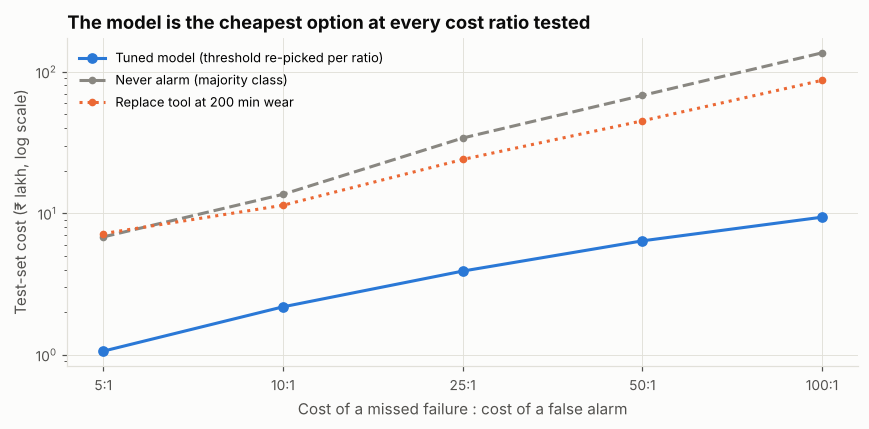

In [27]:
sens = pipeline.sensitivity(train, test, best, oof, probas, preds)
_ = plots.sensitivity(sens, "model_cost_rs", {n: f"{n} cost_rs" for n in baselines},
                      pipeline.sensitivity_title(sens))
sens


**Result.** The cost assumption was varied from 5:1 to 100:1, and the threshold was re-picked on training data each time:

| Cost ratio | Threshold | Model cost | Never alarm | 200-min rule |
| --- | --- | --- | --- | --- |
| 5:1 | 0.32 | ₹1.1 lakh | ₹6.8 lakh | ₹7.2 lakh |
| 10:1 | 0.19 | ₹2.2 lakh | ₹13.6 lakh | ₹11.4 lakh |
| 25:1 | 0.016 | ₹3.9 lakh | ₹34.0 lakh | ₹24.0 lakh |
| 50:1 | 0.008 | ₹6.4 lakh | ₹68.0 lakh | ₹45.0 lakh |
| 100:1 | 0.008 | ₹9.4 lakh | ₹136.0 lakh | ₹87.0 lakh |

The model is the cheapest option at every ratio, saving 81–89% against the better baseline. The threshold falls as missed failures get more expensive, which is the expected direction. The conclusion does not depend on the exact rupee figures; only the threshold does.


## 10. Conclusions, limitations and next steps


**Answer to the question.** From readings available at the start of a job, a tuned gradient boosting model on physics-based features catches **65 of 68** failures in unseen data. It raises 120 false alarms (6% of healthy jobs). At the cost assumption of 25:1, it cuts the cost of mistakes from ₹34 lakh (no model) or ₹24 lakh (replace tools at 200 min) to **₹3.9 lakh**. The result holds across cost ratios from 5:1 to 100:1.

**What made the difference, in order:**
1. **Physics features:** power, temperature difference, and wear × torque (+0.08 to +0.15 PR-AUC for the tree models).
2. **Choosing the threshold by cost instead of 0.5:** 40% cheaper.
3. **Tuning:** under +0.01 PR-AUC.

**Limitations and bias**
* **Synthetic data.** The dataset was generated from documented rules, and the model largely rediscovers them. Real shop data has sensor noise, drift and failures without clean rules, so real-world scores will be lower.
* **No time sequence.** Each row is a separate snapshot with no machine ID or timestamp. Real predictive maintenance uses trends over time, such as rising vibration or temperature, and would need a time-based train/test split.
* **Assumed costs.** The ₹50,000 and ₹2,000 figures are assumptions. The sensitivity analysis shows the ranking is robust, but the threshold should be set from the plant's real costs.
* **Inherently random failures.** Tool-wear failures (random in the 200–240 min window) and failures with no recorded mode can't be predicted from these sensors. The labels are also slightly inconsistent (9 failures without a mode, 18 random-failure flags without a failure).
* **Imbalance across types.** 60% of rows are type L and only 21 failures are type H, so the model is least reliable for H parts. A test set with 68 failures means each miss moves recall by 1.5 points, which is why the bootstrap interval is reported.

**Next steps**
1. Predict the **failure mode**, not just failure yes/no, so the alarm says what to do: change the tool, reduce load, or check cooling.
2. **Calibrate** the probabilities (for example with isotonic regression) so that the threshold follows directly from the cost formula.
3. Give logistic regression **band features** (distance outside the safe power band, distance below 8.6 K) to get a transparent model that may match the trees.
4. Validate on real machine logs with a time-ordered split before trusting it on a shop floor.
